<a href="https://colab.research.google.com/github/noushinnoshu/noushinnoshu/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
# ----------------------------
# Step 1: Import Libraries
# ----------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, accuracy_score, classification_report


In [9]:

movies = pd.read_csv('/content/movies.csv.zip', low_memory=False)
movies.columns = movies.columns.str.strip()
print("Columns in dataset:", movies.columns)
movies.head()

Columns in dataset: Index(['id', 'name', 'year', 'rating', 'certificate', 'duration', 'genre',
       'votes', 'gross_income', 'directors_id', 'directors_name', 'stars_id',
       'stars_name', 'description'],
      dtype='object')


,id,name,year,rating,certificate,duration,genre,votes,gross_income,directors_id,directors_name,stars_id,stars_name,description
0,tt4710316,Best in Sex: 2015 AVN Awards,(2015 TV Special),4.0,TV-MA,94 min,"Adult, News",124.0,0,nm1624094,Gary Miller,"nm4766272,nm2670531,nm4920605,nm6284246","Farrah Laurel Abraham,Asa Akira,Anikka Albrite...",The hottest adult stars and top adult movies a...
1,tt1281857,Naughty Novelist,(2008 Video),3.8,Not Certified,88 min,Adult,174.0,0,nm0045256,John Bacchus,"nm0128986,nm1969196,nm0451160,nm6130462","Darian Caine,Jackie Stevens,A.J. Khan,Arrora",Darian is a successful journalist but when she...
2,tt2294954,2011 AVN Awards Show,(2011 TV Special),5.7,Not Certified,83 min,"Adult, News",39.0,0,"nm1624094,nm0754845","Gary Miller,Timothy E. Sabo","nm2200343,nm2670531,nm1267549,nm3585599","Aubrey Addams,Asa Akira,Monique Alexander,Rave...",Add a Plot
3,tt6843596,Best in Sex: 2017 AVN Awards,(2017 TV Special),4.9,TV-MA,87 min,"Adult, News",225.0,0,nm1624094,Gary Miller,"nm5221471,nm2670531,nm4920605,nm3038816","Amirah Adara,Asa Akira,Anikka Albrite,Britney ...","Considered the industry's highest honor, the A..."
4,tt3705604,AVN Awards 2014,(2014 TV Special),6.7,R,82 min,"Adult, News",101.0,0,nm1624094,Gary Miller,"nm2670531,nm4920605,nm6284246,nm3992720","Asa Akira,Anikka Albrite,August Ames,Jessie An...",Erotic filmmaking superstars Chanel Preston an...


In [16]:
# ----------------------------
# Step 3: Generate Synthetic User Ratings
# ----------------------------
# Create 100 fake users
user_ids = np.random.randint(1, 101, size=1000)

# Randomly assign movies to users
movie_ids = np.random.choice(movies['id'], size=1000)

# Random ratings between 1 and 5
ratings = np.random.uniform(1, 5, size=1000)

# Create ratings dataframe
ratings_df = pd.DataFrame({
    'userId': user_ids,
    'id': movie_ids,
    'rating': ratings
})

# Merge with movies dataframe
data = pd.merge(ratings_df, movies, on='id')

# Rename synthetic rating to 'rating' to avoid confusion
data.rename(columns={'rating_x':'rating'}, inplace=True)

print("Columns after merge:", data.columns)
print("Merged Data Preview:")
data.head()


Columns after merge: Index(['userId', 'id', 'rating', 'name', 'year', 'rating_y', 'certificate',
       'duration', 'genre', 'votes', 'gross_income', 'directors_id',
       'directors_name', 'stars_id', 'stars_name', 'description'],
      dtype='object')
Merged Data Preview:


,userId,id,rating,name,year,rating_y,certificate,duration,genre,votes,gross_income,directors_id,directors_name,stars_id,stars_name,description
0,76,tt5126816,4.888088,S.C.O.T.T the Movie,(2013),11.0,Not Certified,12 min,"Short, Adventure",0,0,nm6911980,James Johnson,"nm7663793,nm6161850,nm6911980,nm4948746","Jack Bartram,Sam Easterby,James Johnson,Scott ...","Social, Connective, Opinionated, Talking, Tech..."
1,66,tt14050494,2.574576,Rvssian with Swae Lee & Shenseea Feat. Young T...,(2020 Music Video),11.0,Not Certified,4 min,Music,0,0,nm5742174,Arrad Rahgoshay,"nm6611654,nm9395170,nm12812243,nm9515679","Swae Lee,Rvssian,Mark Schroeder,Shenseea",Add a Plot
2,93,tt1656588,3.898481,One Piece,(1999– ),8.9,TV-14,0 min,"Animation, Action, Adventure","1,161",0,Anonymous,nm0000000,"nm0065292,nm0157133,nm1310066,nm0387033","Tony Beck,Shigeru Chiba,Tetsuo Gotô,Nobuyuki H...",Bentham puts himself on the line to save Luffy...
3,84,tt3759092,4.232192,Scum,(I) (2014),6.3,Not Certified,12 min,"Short, Crime, Drama",10,0,nm1837488,R. Zachary Shildwachter,"nm6525513,nm6525512,nm4853075,nm4992243","Kyle Adam,Joe Boyer,Kellen Boyle,Kinsley Funari",Exploring the horrifying capabilities of a man...
4,90,tt16974642,4.412328,ASAP,(1995– ),11.0,Not Certified,0 min,"Music, Musical",0,0,/name/nm1203430/,Johnny Manahan,Anonymous,nm0000000,Add a Plot


In [17]:
# ----------------------------
# Step 4: Classification Column (Like / Dislike)
# ----------------------------
data['like'] = data['rating'].apply(lambda x: 1 if x >= 3.5 else 0)

# Preview
data[['userId','id','name','rating','like']].head()


,userId,id,name,rating,like
0,76,tt5126816,S.C.O.T.T the Movie,4.888088,1
1,66,tt14050494,Rvssian with Swae Lee & Shenseea Feat. Young T...,2.574576,0
2,93,tt1656588,One Piece,3.898481,1
3,84,tt3759092,Scum,4.232192,1
4,90,tt16974642,ASAP,4.412328,1


In [19]:
from sklearn.preprocessing import LabelEncoder

# Create a copy to be safe
data_model = data.copy()

# Convert movie 'id' from string to numeric
le = LabelEncoder()
data_model['movie_numeric'] = le.fit_transform(data_model['id'])

# Now we can use 'userId' and 'movie_numeric' as features


In [20]:
# ----------------------------
# Step 5: Regression - Predict Ratings
# ----------------------------
X = data_model[['userId', 'movie_numeric']]  # use numeric movie column
y = data_model['rating']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

y_pred = reg_model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print("Regression Mean Squared Error:", mse)


Regression Mean Squared Error: 1.3150044012880506


In [21]:
# ----------------------------
# Step 6: Classification - Predict Like / Dislike
# ----------------------------
X = data_model[['userId', 'movie_numeric']]  # use numeric movie column
y = data_model['like']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf_model = LogisticRegression(max_iter=1000)
clf_model.fit(X_train, y_train)

y_pred_class = clf_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred_class)
print("Classification Accuracy:", accuracy)
print(classification_report(y_test, y_pred_class))


Classification Accuracy: 0.575
              precision    recall  f1-score   support

           0       0.57      1.00      0.73       115
           1       0.00      0.00      0.00        85

    accuracy                           0.57       200
   macro avg       0.29      0.50      0.37       200
weighted avg       0.33      0.57      0.42       200



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


User Clusters Preview:


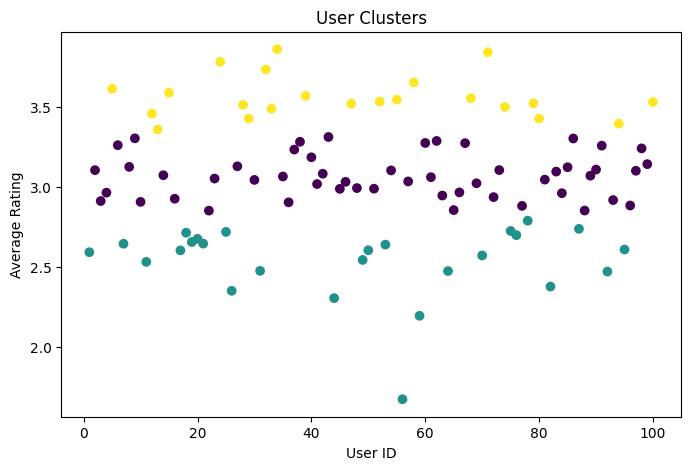

In [23]:
# ----------------------------
# Step 8: Clustering - Segment Users
# ----------------------------
# Average rating per user
user_features = data.groupby('userId')['rating'].mean().reset_index()

# Scale the feature
scaler = StandardScaler()
scaled_data = scaler.fit_transform(user_features[['rating']])

# KMeans clustering
kmeans = KMeans(n_clusters=3, random_state=42)
user_features['cluster'] = kmeans.fit_predict(scaled_data)

print("User Clusters Preview:")
user_features.head()

# Visualize clusters
plt.figure(figsize=(8,5))
plt.scatter(user_features['userId'], user_features['rating'], c=user_features['cluster'], cmap='viridis')
plt.xlabel("User ID")
plt.ylabel("Average Rating")
plt.title("User Clusters")
plt.show()


In [22]:
def recommend_movies(user_id, top_n=5):
    user_data = data_model[data_model['userId'] == user_id]
    not_watched = data_model[~data_model['movie_numeric'].isin(user_data['movie_numeric'])]
    top_movies = not_watched.groupby('name')['rating'].mean().sort_values(ascending=False).head(top_n)
    return top_movies

print("Top 5 movie recommendations for user 1:")
recommend_movies(1)


Top 5 movie recommendations for user 1:


,rating
name,
Tales of Tomorrow,4.999989
Mejor de noche,4.986965
About Faces,4.981325
Sheridan,4.976681
The Daryl Somers Show,4.974837
